# Découpage des données : protocoles `daily` et `temporal`

Le sujet, les données et leur preprocessing, les protocoles et les métriques sont présentés dans `introduction.ipynb`.

Ce notebook **explique et visualise** le découpage des données en **entraînement** et **test**, ainsi que la **cross-validation** associée à chaque protocole.

Le code du découpage se trouve dans le fichier **`decoupage.py`**. Tous les notebooks de modélisation importent ces mêmes fonctions : toute l'équipe utilise donc exactement le même jeu de test et les mêmes plis, et aucun fichier de données découpées n'est stocké.

Pourquoi deux protocoles ? Parce qu'ils répondent à deux questions différentes :

| Protocole | Question posée | Difficulté |
|---|---|---|
| `daily` | Connaissant le reste de l'année, peut-on prédire un jour qu'on n'a pas vu ? | Plus facile : le modèle a vu des jours proches (même saison, même semaine) |
| `temporal` | Avec le passé, peut-on prédire la semaine à venir ? | Plus difficile, mais c'est la situation réelle d'un opérateur de vélos, qui réentraîne son modèle chaque semaine |

**Règle commune** : on ne coupe jamais une journée en deux. Les 24 heures d'un même jour vont toujours dans le même jeu, sinon le modèle pourrait apprendre 7 h et 9 h d'un jour puis être testé sur 8 h du même jour, ce qui serait trop facile.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from decoupage import (charger_donnees, decoupage_daily, cv_daily,
                       decoupage_temporal, cv_temporal, walk_forward)

## 1. Les données

On part du dataset nettoyé par le preprocessing (`charger_donnees()`, voir `introduction.ipynb`) : une ligne par heure de service, du 01/12/2017 au 30/11/2018, avec la cible `rented_bike_count` et toutes les variables (météo, calendrier). Les heures où le service était fermé ont déjà été retirées.

In [2]:
df = charger_donnees()

days = pd.Series(df["date"].unique()).sort_values().reset_index(drop=True)
print(f"{len(df)} heures, {len(days)} jours, du {days.min():%d/%m/%Y} au {days.max():%d/%m/%Y}")

days_per_month = days.groupby(days.dt.to_period("M")).size()
days_per_month.to_frame("jours").T

8465 heures, 353 jours, du 01/12/2017 au 30/11/2018


,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10,2018-11
jours,31,31,28,31,29,30,30,31,31,26,28,27


## 2. Protocole `daily` : 20 % des jours de chaque mois en test

### Principe

On tire au hasard **20 % des jours de chaque mois** pour le test, et on garde les 80 % restants pour l'entraînement. Chaque mois est donc représenté dans les mêmes proportions dans les deux jeux.

```
Déc   Jan   Fév   Mar   Avr   Mai   Juin  Juil  Août  Sep   Oct   Nov
■■□■■ ■■■□■ ■□■■■ ■■■■□ ■■□■■ ■■■□■ □■■■■ ■■□■■ ■■■■□ ■□■■■ ■■■□■ ■■□■■
■ = entraînement   □ = test (≈ 20 % des jours de chaque mois)
```

### Pourquoi stratifier par mois ?

Avec un tirage complètement au hasard, certains mois peuvent être sur- ou sous-représentés dans le test. Le premier découpage du preprocessing mettait par exemple 29 % des jours de février en test, mais seulement 11 % des jours d'octobre. Or la demande dépend énormément de la saison (≈ 200 vélos/h en hiver, ≈ 1 000 en été) : un test trop riche en hiver donne une erreur artificiellement faible. En stratifiant par mois, le test **ressemble à l'année entière**.

In [3]:
train_daily, test_daily = decoupage_daily(df)

print(f"Entraînement : {train_daily['date'].nunique()} jours ({len(train_daily)} heures)")
print(f"Test         : {test_daily['date'].nunique()} jours ({len(test_daily)} heures)")

Entraînement : 283 jours (6785 heures)
Test         : 70 jours (1680 heures)


In [4]:
def share_per_month(train, test):
    count = lambda d: d.drop_duplicates("date").groupby(d["date"].dt.to_period("M")).size()
    table = pd.DataFrame({"jours train": count(train), "jours test": count(test)}).fillna(0).astype(int)
    table["% test"] = (100 * table["jours test"] / (table["jours train"] + table["jours test"])).round().astype(int)
    return table.T


share_per_month(train_daily, test_daily)

date,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10,2018-11
jours train,25,25,22,25,23,24,24,25,25,21,22,22
jours test,6,6,6,6,6,6,6,6,6,5,6,5
% test,19,19,21,19,21,20,20,19,19,19,21,19


Chaque mois a entre 19 et 21 % de ses jours en test (l'écart vient de l'arrondi : 20 % de 28 jours, c'est 5,6 jours, arrondi à 6).

### Cross-validation : `StratifiedGroupKFold`

Pour comparer les modèles sans toucher au test, on découpe l'entraînement en **5 plis** :
- **groupe = la date** : une journée n'est jamais répartie entre entraînement et validation ;
- **stratification = le mois** : chaque pli contient des jours de tous les mois, dans les mêmes proportions.

Le modèle est entraîné sur 4 plis et validé sur le 5e, 5 fois de suite ; on fait la moyenne des 5 erreurs. Le nombre de plis se règle avec le paramètre `n_splits`.

In [5]:
splits_daily = cv_daily(train_daily, n_splits=5)

for k, (idx_train, idx_val) in enumerate(splits_daily, start=1):
    val = train_daily.iloc[idx_val]
    months = val.drop_duplicates("date")["month"].value_counts().sort_index()
    print(f"Pli {k} : validation sur {val['date'].nunique()} jours  |  jours par mois : {months.to_dict()}")

Pli 1 : validation sur 57 jours  |  jours par mois : {1: 5, 2: 5, 3: 5, 4: 4, 5: 5, 6: 5, 7: 5, 8: 5, 9: 4, 10: 4, 11: 5, 12: 5}
Pli 2 : validation sur 56 jours  |  jours par mois : {1: 5, 2: 4, 3: 5, 4: 5, 5: 5, 6: 4, 7: 5, 8: 5, 9: 4, 10: 5, 11: 4, 12: 5}
Pli 3 : validation sur 57 jours  |  jours par mois : {1: 5, 2: 5, 3: 5, 4: 5, 5: 4, 6: 5, 7: 5, 8: 5, 9: 5, 10: 4, 11: 4, 12: 5}
Pli 4 : validation sur 57 jours  |  jours par mois : {1: 5, 2: 4, 3: 5, 4: 4, 5: 5, 6: 5, 7: 5, 8: 5, 9: 4, 10: 5, 11: 5, 12: 5}
Pli 5 : validation sur 56 jours  |  jours par mois : {1: 5, 2: 4, 3: 5, 4: 5, 5: 5, 6: 5, 7: 5, 8: 5, 9: 4, 10: 4, 11: 4, 12: 5}


## 3. Protocole `temporal` : prévoir la semaine suivante (*walk-forward*)

### Principe

On respecte l'**ordre chronologique** : les 80 % premiers jours (du 01/12/2017 au 10/09/2018) servent d'entraînement, les 20 % derniers (du 11/09 au 30/11/2018) de test. La coupure tombe entre deux journées.

Mais au lieu d'entraîner une seule fois puis de prédire les 71 jours de test d'un coup, on **simule le travail d'un opérateur** : chaque semaine, il réentraîne son modèle avec **tout le passé disponible** et prévoit **la semaine suivante**.

```
Semaine 1 du test :  entraîne sur 01/12 → 10/09   prédit 11/09 → 17/09
Semaine 2 du test :  entraîne sur 01/12 → 17/09   prédit 20/09 → 26/09
...
Semaine 10        :  entraîne sur 01/12 → 22/11   prédit 23/11 → 30/11
```

Une « semaine » regroupe 7 **jours de service** : les jours où le service était fermé (par exemple les 18 et 19/09) ont été retirés par le preprocessing, donc certaines semaines s'étalent sur un peu plus de 7 jours du calendrier.

### Pourquoi ce protocole ?

C'est la situation **réelle** : on prévoit toujours des jours qui ne sont pas encore arrivés, et on ne doit jamais apprendre sur le futur. Avec un seul entraînement, le modèle prédirait fin novembre avec des données arrêtées au 10 septembre et n'aurait jamais vu l'automne. En réentraînant chaque semaine, il intègre au fur et à mesure les premières semaines d'automne, comme le ferait un opérateur.

In [6]:
# La colonne "semaine" (1 à 10) numérote les semaines de test pour le walk-forward
train_temporal, test_temporal = decoupage_temporal(df)

print(f"Entraînement : du {train_temporal['date'].min():%d/%m/%Y} au {train_temporal['date'].max():%d/%m/%Y} "
      f"({train_temporal['date'].nunique()} jours, {len(train_temporal)} heures)")
print(f"Test         : du {test_temporal['date'].min():%d/%m/%Y} au {test_temporal['date'].max():%d/%m/%Y} "
      f"({test_temporal['date'].nunique()} jours, {len(test_temporal)} heures)")

test_temporal.groupby("semaine")["date"].agg(début="min", fin="max", jours="nunique")

Entraînement : du 01/12/2017 au 10/09/2018 (282 jours, 6768 heures)
Test         : du 11/09/2018 au 30/11/2018 (71 jours, 1697 heures)


,début,fin,jours
semaine,,,
1,2018-09-11,2018-09-17,7
2,2018-09-20,2018-09-26,7
3,2018-09-27,2018-10-07,7
4,2018-10-08,2018-10-15,7
5,2018-10-16,2018-10-22,7
6,2018-10-23,2018-10-29,7
7,2018-10-30,2018-11-07,7
8,2018-11-08,2018-11-15,7
9,2018-11-16,2018-11-22,7


### Évaluation finale : une semaine à la fois

La fonction `walk_forward` (dans `decoupage.py`) produit les 10 étapes de l'évaluation finale. À chaque étape, on obtient le **passé** (l'entraînement + les semaines de test déjà écoulées) et la **semaine à prédire**. Dans les notebooks de modélisation, on entraîne le modèle sur le passé, on prédit la semaine, puis on calcule l'erreur sur l'ensemble des prédictions.

In [7]:
for past, week in walk_forward(train_temporal, test_temporal):
    print(f"Entraîne sur {past['date'].min():%d/%m} → {past['date'].max():%d/%m} ({past['date'].nunique()} jours)"
          f"   prédit {week['date'].min():%d/%m} → {week['date'].max():%d/%m}")

Entraîne sur 01/12 → 10/09 (282 jours)   prédit 11/09 → 17/09
Entraîne sur 01/12 → 17/09 (289 jours)   prédit 20/09 → 26/09
Entraîne sur 01/12 → 26/09 (296 jours)   prédit 27/09 → 07/10
Entraîne sur 01/12 → 07/10 (303 jours)   prédit 08/10 → 15/10
Entraîne sur 01/12 → 15/10 (310 jours)   prédit 16/10 → 22/10
Entraîne sur 01/12 → 22/10 (317 jours)   prédit 23/10 → 29/10
Entraîne sur 01/12 → 29/10 (324 jours)   prédit 30/10 → 07/11
Entraîne sur 01/12 → 07/11 (331 jours)   prédit 08/11 → 15/11
Entraîne sur 01/12 → 15/11 (338 jours)   prédit 16/11 → 22/11
Entraîne sur 01/12 → 22/11 (345 jours)   prédit 23/11 → 30/11


### Cross-validation : `TimeSeriesSplit` semaine par semaine

Même logique pour comparer les modèles sur l'entraînement : chaque pli entraîne sur **tout ce qui précède** et valide sur **les 7 jours suivants** (`TimeSeriesSplit` avec `test_size=7`, appliqué à la liste des jours). Une cross-validation classique mélangerait les périodes et ferait apprendre sur le futur.

La validation commence le **1er avril** (paramètre `debut_validation`) : les plis plus précoces n'auraient que quelques semaines d'hiver pour apprendre, ce qui ne ressemble pas à la situation du test et rendrait les scores très instables.

In [8]:
splits_temporal = cv_temporal(train_temporal, debut_validation="2018-04-01", jours_par_pli=7)
n_splits_temporal = len(splits_temporal)

folds = []
for idx_train, idx_val in splits_temporal:
    d_tr, d_val = train_temporal["date"].iloc[idx_train].unique(), train_temporal["date"].iloc[idx_val].unique()
    folds.append({"entraînement": f"{pd.Timestamp(d_tr.min()):%d/%m} → {pd.Timestamp(d_tr.max()):%d/%m}", "jours entraînement": len(d_tr),
                  "validation": f"{pd.Timestamp(d_val.min()):%d/%m} → {pd.Timestamp(d_val.max()):%d/%m}"})

folds = pd.DataFrame(folds, index=pd.RangeIndex(1, len(folds) + 1, name="pli"))
print(f"{n_splits_temporal} plis de validation d'une semaine")
pd.concat([folds.head(3), folds.tail(3)])

23 plis de validation d'une semaine


,entraînement,jours entraînement,validation
pli,,,
1,01/12 → 31/03,121,01/04 → 07/04
2,01/12 → 07/04,128,08/04 → 15/04
3,01/12 → 15/04,135,16/04 → 22/04
21,01/12 → 20/08,261,21/08 → 27/08
22,01/12 → 27/08,268,28/08 → 03/09
23,01/12 → 03/09,275,04/09 → 10/09


## 4. Visualisation des deux protocoles

Chaque barre verticale est un jour, et chaque ligne une étape d'entraînement / évaluation.

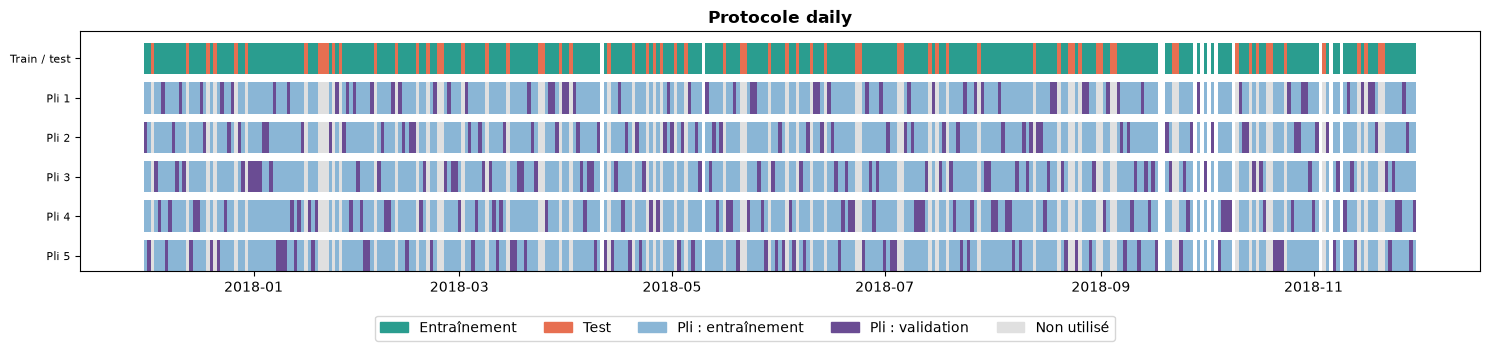

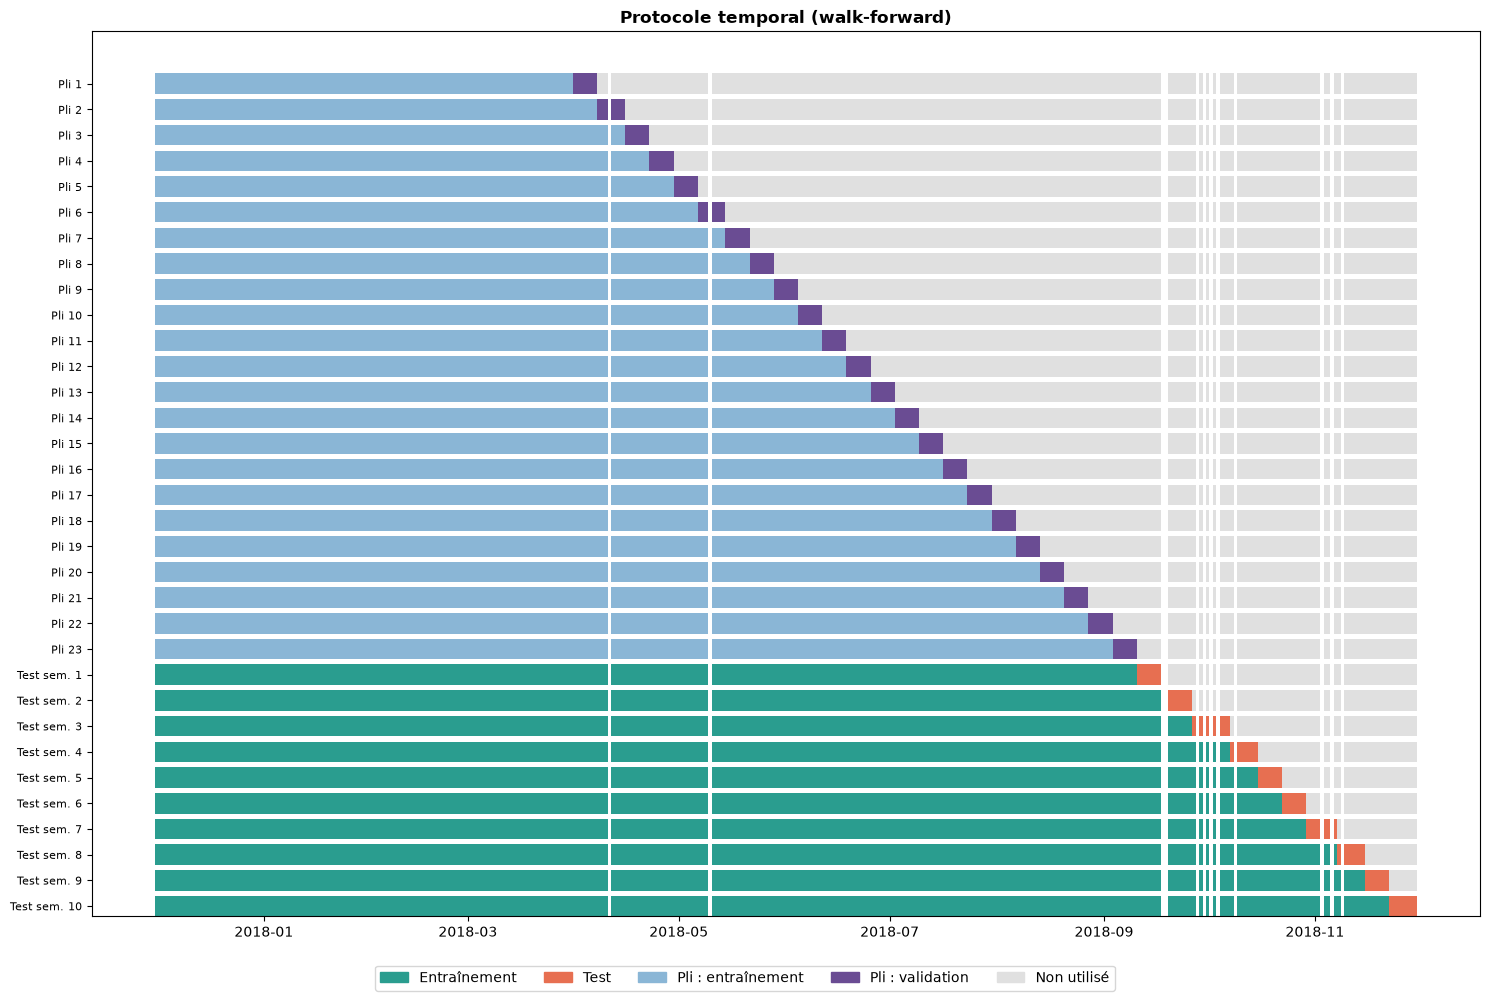

In [9]:
COLORS = {"train": "#2a9d8f", "test": "#e76f51", "cv_train": "#8ab6d6", "cv_val": "#6a4c93", "unused": "#e0e0e0"}


def color_row(train_days, eval_days, train_color, eval_color):
    row = pd.Series(COLORS["unused"], index=days)
    row[row.index.isin(train_days)] = train_color
    row[row.index.isin(eval_days)] = eval_color
    return row


def plot_rows(ax, rows, labels, title):
    for level, colors in enumerate(rows):
        ax.bar(days, 0.8, bottom=-level - 0.4, width=1.0, color=colors.values)
    ax.set_yticks(range(0, -len(rows), -1))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(title, fontweight="bold")
    ax.grid(False)


legend = ([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()],
          ["Entraînement", "Test", "Pli : entraînement", "Pli : validation", "Non utilisé"])

# Protocole daily : découpage train/test + 5 plis
rows = [color_row(train_daily["date"], test_daily["date"], COLORS["train"], COLORS["test"])]
rows += [color_row(train_daily["date"].iloc[tr], train_daily["date"].iloc[va], COLORS["cv_train"], COLORS["cv_val"])
         for tr, va in splits_daily]
fig, ax = plt.subplots(figsize=(15, 3.5))
plot_rows(ax, rows, ["Train / test"] + [f"Pli {k}" for k in range(1, 6)], "Protocole daily")
fig.legend(*legend, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

# Protocole temporal : plis de cross-validation puis semaines du test
rows = [color_row(train_temporal["date"].iloc[tr], train_temporal["date"].iloc[va], COLORS["cv_train"], COLORS["cv_val"])
        for tr, va in splits_temporal]
rows += [color_row(past["date"], week["date"], COLORS["train"], COLORS["test"])
         for past, week in walk_forward(train_temporal, test_temporal)]
labels = [f"Pli {k}" for k in range(1, n_splits_temporal + 1)] + [f"Test sem. {w}" for w in range(1, 11)]
fig, ax = plt.subplots(figsize=(15, 10))
plot_rows(ax, rows, labels, "Protocole temporal (walk-forward)")
fig.legend(*legend, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

- **`daily`** : les jours de test (orange) sont **dispersés sur toute l'année**, à peu près 6 par mois. Dans chaque pli, les jours de validation (violet) sont eux aussi répartis sur tous les mois.
- **`temporal`** : on avance **une semaine à la fois**. En cross-validation (lignes du haut), chaque pli valide sur la semaine qui suit son entraînement, d'avril à début septembre. Pour le test (lignes du bas), chaque semaine est prédite par un modèle entraîné sur tout ce qui précède, y compris les semaines de test déjà écoulées.
- Les trous blancs sont les jours où le service était fermé, retirés par le preprocessing.

## 5. Utilisation dans les notebooks de modélisation

Aucun fichier n'est exporté : chaque notebook importe les fonctions de `decoupage.py` et obtient exactement le même découpage.

**Protocole `daily`** :
```python
from decoupage import charger_donnees, decoupage_daily, cv_daily, variables, CIBLE

train, test = decoupage_daily(charger_donnees())
X_train, y_train = train[variables(train)], train[CIBLE]
X_test, y_test = test[variables(test)], test[CIBLE]
splits = cv_daily(train, n_splits=5)       # à passer en cv=splits dans cross_validate
```

**Protocole `temporal`** :
```python
from decoupage import charger_donnees, decoupage_temporal, cv_temporal, walk_forward, variables, CIBLE

train, test = decoupage_temporal(charger_donnees())
splits = cv_temporal(train)                # 23 plis d'une semaine, pour choisir le modèle
for past, week in walk_forward(train, test):
    ...                                    # évaluation finale : entraîne sur past, prédit week
```
